# Capstone Project 2: Spam Detection using Deep Learning (NLP)

In [7]:
import os
import kagglehub
import pandas as pd

# Download latest version
path = kagglehub.dataset_download("team-ai/spam-text-message-classification")

print("Path to dataset files:", path)

# Load the CSV file
csv_path = os.path.join(path, "SPAM text message 20170820 - Data.csv")
df = pd.read_csv(csv_path)
df.head()

Path to dataset files: C:\Users\singh\.cache\kagglehub\datasets\team-ai\spam-text-message-classification\versions\1


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 1. Exploratory Data Analysis: Class Imbalance & Message Length

C:\Users\singh\AppData\Local\Temp\ipykernel_13996\2002225055.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Category", palette=["#2b5c8f", "#d95f02"], ax=axes[0])
C:\Users\singh\AppData\Local\Temp\ipykernel_13996\2002225055.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


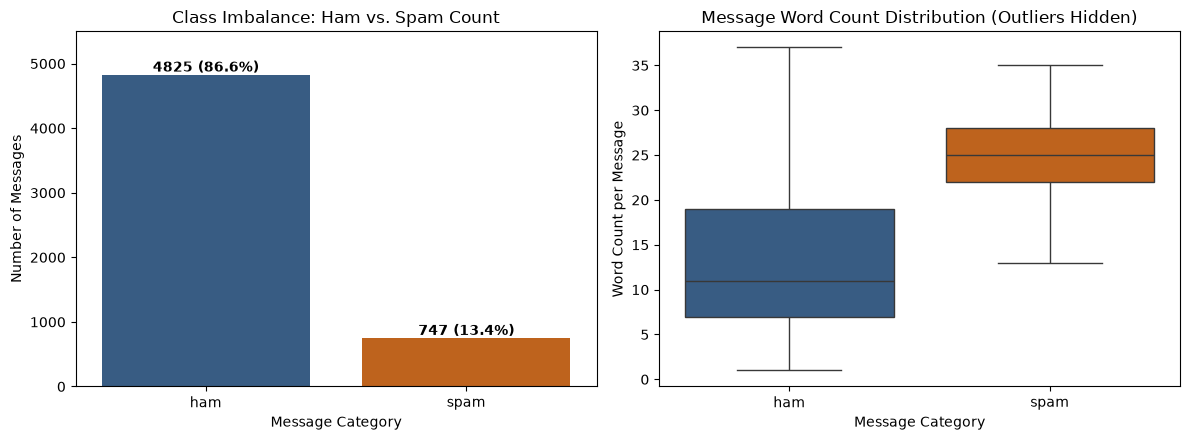

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

df["word_count"] = df["Message"].apply(lambda x: len(str(x).split()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.countplot(data=df, x="Category", palette=["#2b5c8f", "#d95f02"], ax=axes[0])
axes[0].set_title("Class Imbalance: Ham vs. Spam Count")
axes[0].set_xlabel("Message Category")
axes[0].set_ylabel("Number of Messages")

for p in axes[0].patches:
    count = int(p.get_height())
    pct = (count / len(df)) * 100
    axes[0].annotate(
        f"{count} ({pct:.1f}%)",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="bottom",
        fontweight="bold",
    )
axes[0].set_ylim(0, 5500)

sns.boxplot(
    data=df,
    x="Category",
    y="word_count",
    palette=["#2b5c8f", "#d95f02"],
    ax=axes[1],
    showfliers=False,
)
axes[1].set_title("Message Word Count Distribution (Outliers Hidden)")
axes[1].set_xlabel("Message Category")
axes[1].set_ylabel("Word Count per Message")

plt.tight_layout()
plt.show()

## 2. Basic NLP Text Cleaning & Label Encoding

In [9]:
import re


def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


df["clean_message"] = df["Message"].apply(clean_text)
df["label"] = df["Category"].map({"ham": 0, "spam": 1})
df[["Category", "label", "clean_message"]].head()

,Category,label,clean_message
0,ham,0,go until jurong point crazy available only in ...
1,ham,0,ok lar joking wif u oni
2,spam,1,free entry in a wkly comp to win fa cup final ...
3,ham,0,u dun say so early hor u c already then say
4,ham,0,nah i dont think he goes to usf he lives aroun...


## 3. Train-Test Split (80-20), Tokenization & Padding

In [10]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

X_train, X_test, y_train, y_test = train_test_split(
    df["clean_message"], df["label"], test_size=0.20, random_state=42
)

vocab_size = 5000
max_len = 100

tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_pad = pad_sequences(
    tokenizer.texts_to_sequences(X_train), maxlen=max_len, padding="post"
)
X_test_pad = pad_sequences(
    tokenizer.texts_to_sequences(X_test), maxlen=max_len, padding="post"
)

print("Training Data Shape:", X_train_pad.shape)
print("Testing Data Shape:", X_test_pad.shape)

Training Data Shape: (4457, 100)
Testing Data Shape: (1115, 100)


## 4. Build & Train the TensorFlow Deep Learning Model

In [11]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GlobalAveragePooling1D, Dense

model = Sequential(
    [
        Embedding(input_dim=vocab_size, output_dim=16, input_length=max_len),
        GlobalAveragePooling1D(),
        Dense(16, activation="relu"),
        Dense(1, activation="sigmoid"),
    ]
)

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

history = model.fit(
    X_train_pad, y_train, epochs=15, batch_size=32, validation_data=(X_test_pad, y_test)
)

Epoch 1/15


c:\Users\singh\OneDrive\Desktop\capstone 2\.venv\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


140/140 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8618 - loss: 0.3884 - val_accuracy: 0.8664 - val_loss: 0.3770
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8658 - loss: 0.3706 - val_accuracy: 0.8664 - val_loss: 0.3666
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8658 - loss: 0.3596 - val_accuracy: 0.8664 - val_loss: 0.3528
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8658 - loss: 0.3426 - val_accuracy: 0.8664 - val_loss: 0.3281
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8658 - loss: 0.3065 - val_accuracy: 0.8664 - val_loss: 0.2840
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8806 - loss: 0.2459 - val_accuracy: 0.9265 - val_loss: 0.2117
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9372 - loss: 0.1702 - val_accuracy: 0.9758 - val_loss: 0.1743
Epoch 8/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9675 - loss: 0.1174 - val_accuracy: 0.9767 - val_

## 5. Model Evaluation & Test Set Visualizations

Training Accuracy: 98.70% | Training Loss: 0.0413
Test Accuracy:     98.21% | Test Loss:     0.0619

Classification Report (Test Set):
              precision    recall  f1-score   support

     Ham (0)       0.99      0.99      0.99       966
    Spam (1)       0.95      0.91      0.93       149

    accuracy                           0.98      1115
   macro avg       0.97      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



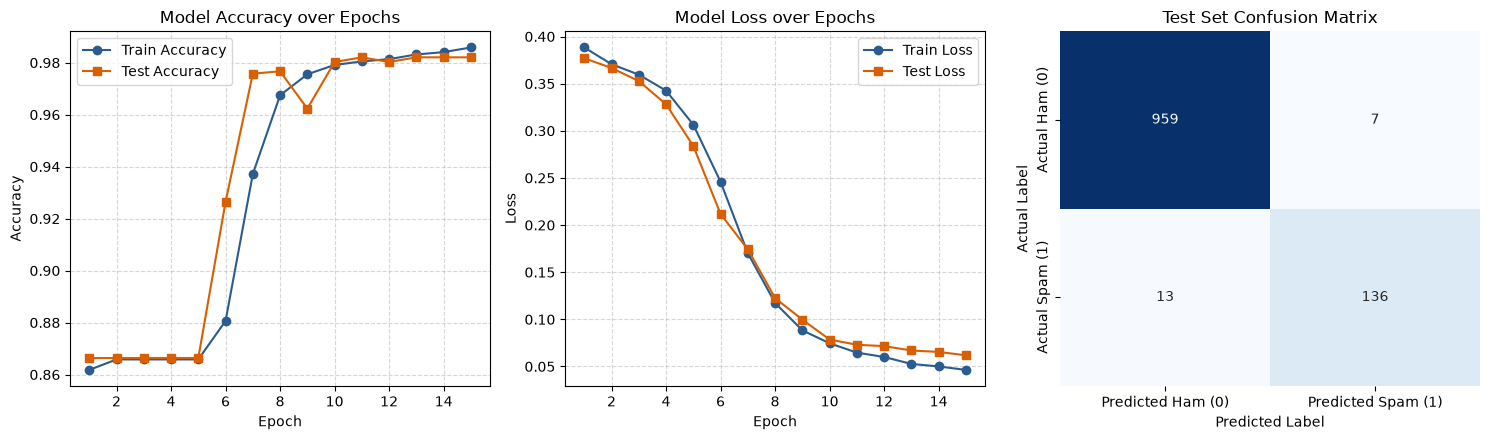

In [12]:
from sklearn.metrics import confusion_matrix, classification_report

train_loss, train_acc = model.evaluate(X_train_pad, y_train, verbose=0)
test_loss, test_acc = model.evaluate(X_test_pad, y_test, verbose=0)
print(f"Training Accuracy: {train_acc * 100:.2f}% | Training Loss: {train_loss:.4f}")
print(f"Test Accuracy:     {test_acc * 100:.2f}% | Test Loss:     {test_loss:.4f}\n")

y_pred_prob = model.predict(X_test_pad, verbose=0).flatten()
y_pred = (y_pred_prob >= 0.5).astype(int)

print("Classification Report (Test Set):")
print(classification_report(y_test, y_pred, target_names=["Ham (0)", "Spam (1)"]))

cm = confusion_matrix(y_test, y_pred)
epochs_range = range(1, len(history.history["accuracy"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].plot(
    epochs_range,
    history.history["accuracy"],
    marker="o",
    label="Train Accuracy",
    color="#2b5c8f",
)
axes[0].plot(
    epochs_range,
    history.history["val_accuracy"],
    marker="s",
    label="Test Accuracy",
    color="#d95f02",
)
axes[0].set_title("Model Accuracy over Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Loss Curve
axes[1].plot(
    epochs_range,
    history.history["loss"],
    marker="o",
    label="Train Loss",
    color="#2b5c8f",
)
axes[1].plot(
    epochs_range,
    history.history["val_loss"],
    marker="s",
    label="Test Loss",
    color="#d95f02",
)
axes[1].set_title("Model Loss over Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Predicted Ham (0)", "Predicted Spam (1)"],
    yticklabels=["Actual Ham (0)", "Actual Spam (1)"],
    ax=axes[2],
)
axes[2].set_title("Test Set Confusion Matrix")
axes[2].set_xlabel("Predicted Label")
axes[2].set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

## 6. Save Model and Tokenizer for Streamlit App

In [13]:
import pickle

model.save("spam_model.h5")
with open("tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

print("Saved spam_model.h5 and tokenizer.pkl successfully!")

Saved spam_model.h5 and tokenizer.pkl successfully!
